# IS432 Final Project
## Data Section

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors

In [ ]:
df = pd.read_csv('AgenticAI_Leadership_Dataset.csv')

print(df.head())

   Record_ID            Industry Organization_Size Leadership_Function  \
0  AAI-00001           Education             Small          Operations   
1  AAI-00002       Manufacturing             Small          Operations   
2  AAI-00003  Telecommunications            Medium          Operations   
3  AAI-00004              Energy             Large     Human Resources   
4  AAI-00005  Financial Services             Small           Marketing   

  AI_Maturity_Level                  Agent_Type            Use_Case_Area  \
0             Early       Risk Monitoring Agent       Process Automation   
1          Advanced  Knowledge Management Agent       Demand Forecasting   
2           Leading   Workflow Automation Agent       Process Automation   
3           Leading   Workflow Automation Agent       Workforce Planning   
4          Advanced           Procurement Agent  Content Personalization   

  Agent_Autonomy_Level Decision_Making_Type  Context_Awareness_Score  \
0                  Low    

In [ ]:
df.isna().sum()

,0
Record_ID,0
Industry,0
Organization_Size,0
Leadership_Function,0
AI_Maturity_Level,0
Agent_Type,0
Use_Case_Area,0
Agent_Autonomy_Level,0
Decision_Making_Type,0
Context_Awareness_Score,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(5500, 20)

### Summary Statistics

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 20 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Record_ID                         5500 non-null   object 
 1   Industry                          5500 non-null   object 
 2   Organization_Size                 5500 non-null   object 
 3   Leadership_Function               5500 non-null   object 
 4   AI_Maturity_Level                 5500 non-null   object 
 5   Agent_Type                        5500 non-null   object 
 6   Use_Case_Area                     5500 non-null   object 
 7   Agent_Autonomy_Level              5500 non-null   object 
 8   Decision_Making_Type              5500 non-null   object 
 9   Context_Awareness_Score           5500 non-null   float64
 10  Task_Complexity_Level             5500 non-null   object 
 11  Human_Oversight_Level             5500 non-null   object 
 12  Explai

In [ ]:
df[["Context_Awareness_Score", "Task_Success_Rate", "Response_Time_Seconds", "Productivity_Improvement_Percent", "Leadership_Trust_Score"]].describe()


,Context_Awareness_Score,Task_Success_Rate,Response_Time_Seconds,Productivity_Improvement_Percent,Leadership_Trust_Score
count,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000
mean,54.123473,73.737655,7.490287,12.748782,62.254109
std,15.654109,10.201866,2.589438,5.794155,13.730996
min,20.000000,42.000000,1.200000,1.500000,25.000000
25%,42.700000,66.800000,5.610000,8.375000,53.400000
50%,54.750000,74.000000,7.320000,12.900000,63.800000
75%,65.725000,81.000000,9.240000,17.000000,72.600000
max,97.500000,98.000000,16.020000,28.400000,96.800000


### Boxplots

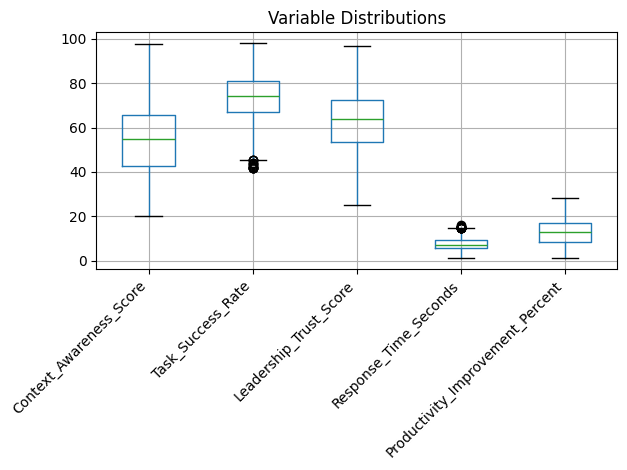

In [ ]:
df.boxplot(column=["Context_Awareness_Score", "Task_Success_Rate", "Leadership_Trust_Score", "Response_Time_Seconds", "Productivity_Improvement_Percent"])
plt.title("Variable Distributions")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

cols = ["Context_Awareness_Score", "Task_Success_Rate",
        "Leadership_Trust_Score", "Response_Time_Seconds",
        "Productivity_Improvement_Percent"]

outlier_counts = {}

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]
    outlier_counts[col] = len(outliers)

outlier_counts

{'Context_Awareness_Score': 0,
 'Task_Success_Rate': 14,
 'Leadership_Trust_Score': 0,
 'Response_Time_Seconds': 16,
 'Productivity_Improvement_Percent': 0}


## Regression Analysis

### Simple Regression


In [ ]:
y = df["Leadership_Trust_Score"]

X1 = df[["Task_Success_Rate"]]
X1 = sm.add_constant(X1)

model1 = sm.OLS(y,X1).fit()
print(model1.summary())

                              OLS Regression Results                              
Dep. Variable:     Leadership_Trust_Score   R-squared:                       0.139
Model:                                OLS   Adj. R-squared:                  0.139
Method:                     Least Squares   F-statistic:                     890.9
Date:                    Wed, 06 May 2026   Prob (F-statistic):          1.49e-181
Time:                            18:16:37   Log-Likelihood:                -21799.
No. Observations:                    5500   AIC:                         4.360e+04
Df Residuals:                        5498   BIC:                         4.361e+04
Df Model:                               1                                         
Covariance Type:                nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------

### Multiple Regression

In [ ]:
X2 = df[["Task_Success_Rate", "Response_Time_Seconds", "Productivity_Improvement_Percent"]]
X2 = sm.add_constant(X2)

model2 = sm.OLS(y,X2).fit()
print(model2.summary())

                              OLS Regression Results                              
Dep. Variable:     Leadership_Trust_Score   R-squared:                       0.414
Model:                                OLS   Adj. R-squared:                  0.414
Method:                     Least Squares   F-statistic:                     1294.
Date:                    Wed, 06 May 2026   Prob (F-statistic):               0.00
Time:                            18:16:37   Log-Likelihood:                -20742.
No. Observations:                    5500   AIC:                         4.149e+04
Df Residuals:                        5496   BIC:                         4.152e+04
Df Model:                               3                                         
Covariance Type:                nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------

In [ ]:
X3 = df[["Task_Success_Rate", "Response_Time_Seconds", "Productivity_Improvement_Percent", "Context_Awareness_Score"]]
X3 = sm.add_constant(X3)

model3 = sm.OLS(y,X3).fit()
print(model3.summary())

                              OLS Regression Results                              
Dep. Variable:     Leadership_Trust_Score   R-squared:                       0.477
Model:                                OLS   Adj. R-squared:                  0.476
Method:                     Least Squares   F-statistic:                     1251.
Date:                    Wed, 06 May 2026   Prob (F-statistic):               0.00
Time:                            18:16:37   Log-Likelihood:                -20432.
No. Observations:                    5500   AIC:                         4.087e+04
Df Residuals:                        5495   BIC:                         4.091e+04
Df Model:                               4                                         
Covariance Type:                nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------

### VIF

In [ ]:
x = df[["Task_Success_Rate", "Response_Time_Seconds", "Productivity_Improvement_Percent", "Context_Awareness_Score"]]

vif = pd.DataFrame()
vif["variable"] = x.columns
vif["VIF"] = [variance_inflation_factor(x.values, i) for i in range(x.shape[1])]

print(vif)

                           variable        VIF
0                 Task_Success_Rate  21.240837
1             Response_Time_Seconds  13.367612
2  Productivity_Improvement_Percent  11.225531
3           Context_Awareness_Score  25.433482


PCA (VIF>5)

In [ ]:
# vif > 5, ran pca based on my data.
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)

Explained variance ratio: [0.61900515 0.26175306]


In [ ]:
X_pca = sm.add_constant(x_pca)
y = df["Leadership_Trust_Score"]

model_pca = sm.OLS(y,X_pca).fit()
print(model_pca.summary())

                              OLS Regression Results                              
Dep. Variable:     Leadership_Trust_Score   R-squared:                       0.333
Model:                                OLS   Adj. R-squared:                  0.332
Method:                     Least Squares   F-statistic:                     1369.
Date:                    Wed, 06 May 2026   Prob (F-statistic):               0.00
Time:                            18:16:37   Log-Likelihood:                -21100.
No. Observations:                    5500   AIC:                         4.221e+04
Df Residuals:                        5497   BIC:                         4.223e+04
Df Model:                               2                                         
Covariance Type:                nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       

### Nonlinear Regression


In [ ]:
y = df["Leadership_Trust_Score"]

In [ ]:
df["Task_Success_Rate_sq"] = df["Task_Success_Rate"]**2

X = df[["Task_Success_Rate", "Task_Success_Rate_sq"]]
X = sm.add_constant(X)

model = sm.OLS(y,X).fit()


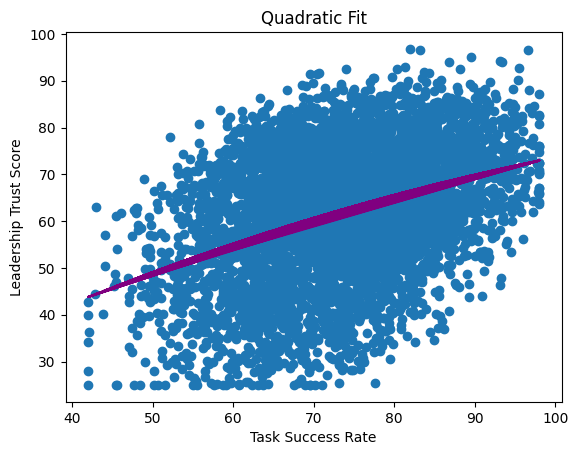

In [ ]:
y_pred = model.predict(X)

plt.figure()
plt.scatter(df["Task_Success_Rate"], df["Leadership_Trust_Score"])
plt.plot(df["Task_Success_Rate"], y_pred, color="purple")

plt.xlabel("Task Success Rate")
plt.ylabel("Leadership Trust Score")
plt.title("Quadratic Fit")

plt.show()


## Regression Tree & Prediction Analysis

### Data Split

In [ ]:
X = df[["Task_Success_Rate", "Response_Time_Seconds", "Productivity_Improvement_Percent", "Context_Awareness_Score"]]
y = df["Leadership_Trust_Score"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

### Run Regression and Calculate RMSE

In [ ]:
X_train_ols = sm.add_constant(X_train)
# got error: to fix add_constant applied after split since OLS and tree share the same split
X_test_ols = sm.add_constant(X_test)
# add_constant applied after split since OLS and tree share the same split

ols_model = sm.OLS(y_train,X_train_ols).fit()
print(ols_model.summary())

                              OLS Regression Results                              
Dep. Variable:     Leadership_Trust_Score   R-squared:                       0.483
Model:                                OLS   Adj. R-squared:                  0.483
Method:                     Least Squares   F-statistic:                     899.2
Date:                    Wed, 06 May 2026   Prob (F-statistic):               0.00
Time:                            18:16:37   Log-Likelihood:                -14305.
No. Observations:                    3850   AIC:                         2.862e+04
Df Residuals:                        3845   BIC:                         2.865e+04
Df Model:                               4                                         
Covariance Type:                nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------

In [ ]:
y_pred_ols = ols_model.predict(X_test_ols)

rmse_ols = np.sqrt(mean_squared_error(y_test, y_pred_ols))
print("Test RMSE (OLS):", rmse_ols)

Test RMSE (OLS): 9.918819011703556


### Cross validation and RMSE For Each Fold

In [ ]:
scores_ols = cross_val_score(
    DecisionTreeRegressor(max_depth=2, random_state=1),
    X, y,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

print("CV RMSE for each fold:", -scores_ols)
print("Average CV RMSE:", (-scores_ols).mean())

CV RMSE for each fold: [12.27051707 12.08641617 12.36069375 11.66604008 12.61808357]
Average CV RMSE: 12.200350129124562


### Run Regression Tree and Plot

In [ ]:
model = DecisionTreeRegressor(max_depth=2, random_state=1)
model.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=2, random_state=1)

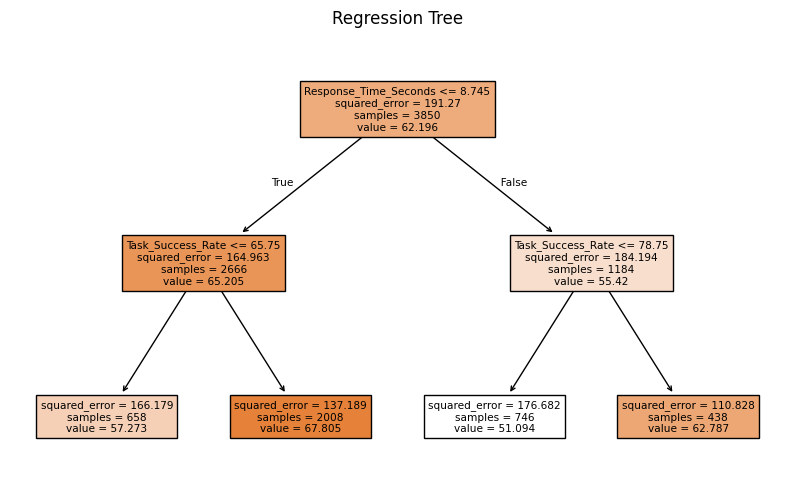

In [ ]:
plt.figure(figsize=(10,6))
plot_tree(model, feature_names=["Task_Success_Rate", "Response_Time_Seconds", "Productivity_Improvement_Percent", "Context_Awareness_Score"],
          filled=True)
plt.title("Regression Tree")
plt.show()

In [ ]:
y_pred = model.predict(X_test)
print(y_pred)

[67.80468127 67.80468127 67.80468127 ... 51.09356568 67.80468127
 67.80468127]


In [ ]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("Test RMSE:", rmse)

Test RMSE: 12.117458631274932


### Cross-Validation to Evaluate Tree Model

In [ ]:
scores = cross_val_score(
    DecisionTreeRegressor(max_depth=2, random_state=1),
    X, y,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

print("CV RMSE for each fold:", -scores)
print("Average CV RMSE:", (-scores).mean())

CV RMSE for each fold: [12.27051707 12.08641617 12.36069375 11.66604008 12.61808357]
Average CV RMSE: 12.200350129124562


## Causal Inference Analysis

In [ ]:
df["treatment"] = (df["Data_Privacy_Compliance"] == "Yes").astype(int)

In [ ]:
print(df.groupby("treatment")[["Task_Success_Rate", "Response_Time_Seconds", "Productivity_Improvement_Percent", "Context_Awareness_Score"]].mean())



           Task_Success_Rate  Response_Time_Seconds  \
treatment                                             
0                  67.131780               7.694343   
1                  75.585086               7.433220   

           Productivity_Improvement_Percent  Context_Awareness_Score  
treatment                                                             
0                                 10.819884                55.059235  
1                                 13.288227                53.861773  


In [ ]:
X = df[["Task_Success_Rate", "Response_Time_Seconds", "Productivity_Improvement_Percent", "Context_Awareness_Score"]]
y = df["treatment"]

In [ ]:
model = LogisticRegression(max_iter=1000)
model.fit(X,y)

LogisticRegression(max_iter=1000)

### Baseline Multiple Regression

In [ ]:
import statsmodels.api as sm

X_baseline = df[["Task_Success_Rate", "Response_Time_Seconds", "Productivity_Improvement_Percent", "Context_Awareness_Score"]]
X_baseline = sm.add_constant(X_baseline)

y_reg = df["Leadership_Trust_Score"]

baseline_model = sm.OLS(y_reg, X_baseline).fit()
print(baseline_model.summary())

                              OLS Regression Results                              
Dep. Variable:     Leadership_Trust_Score   R-squared:                       0.477
Model:                                OLS   Adj. R-squared:                  0.476
Method:                     Least Squares   F-statistic:                     1251.
Date:                    Wed, 06 May 2026   Prob (F-statistic):               0.00
Time:                            18:16:38   Log-Likelihood:                -20432.
No. Observations:                    5500   AIC:                         4.087e+04
Df Residuals:                        5495   BIC:                         4.091e+04
Df Model:                               4                                         
Covariance Type:                nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------

### PSM Dataset

In [ ]:
df["propensity_score"] = model.predict_proba(X)[:,1]

In [ ]:
print(df[["treatment", "propensity_score"]].head())

   treatment  propensity_score
0          1          0.925405
1          0          0.488356
2          1          0.769927
3          0          0.885810
4          1          0.872089


In [ ]:
print(df.groupby("treatment")["propensity_score"].mean())

treatment
0    0.622975
1    0.825775
Name: propensity_score, dtype: float64


In [ ]:
control = df[df["treatment"] == 0]
treated = df[df["treatment"] == 1]
nn = NearestNeighbors(n_neighbors = 1)
nn.fit(control[["propensity_score"]])
distances, indices = nn.kneighbors(treated[["propensity_score"]])

In [ ]:
matched_control = control.iloc[indices.flatten()].copy()
matched_control.index = treated.index

matched_df = pd.concat([treated, matched_control], axis=0)

print(matched_df.head())
print("Matched dataset size:", matched_df.shape)

   Record_ID            Industry Organization_Size Leadership_Function  \
0  AAI-00001           Education             Small          Operations   
2  AAI-00003  Telecommunications            Medium          Operations   
4  AAI-00005  Financial Services             Small           Marketing   
5  AAI-00006  Financial Services            Medium           Marketing   
6  AAI-00007              Retail            Medium                  IT   

  AI_Maturity_Level                 Agent_Type            Use_Case_Area  \
0             Early      Risk Monitoring Agent       Process Automation   
2           Leading  Workflow Automation Agent       Process Automation   
4          Advanced          Procurement Agent  Content Personalization   
5          Advanced  Customer Experience Agent    Campaign Optimization   
6          Advanced     Decision Support Agent          Incident Triage   

  Agent_Autonomy_Level Decision_Making_Type  Context_Awareness_Score  ...  \
0                  Low     

In [ ]:
def compute_smd(data, treatment_col, variables):
  smd_results = []

  treated_group = data[data[treatment_col] == 1]
  control_group = data[data[treatment_col] == 0]

  for var in variables:
    mean_t = treated_group[var].mean()
    mean_c = control_group[var].mean()

    std_t = treated_group[var].std()
    std_c = control_group[var].std()

    pooled_std = np.sqrt((std_t**2 + std_c**2) / 2)
    smd = (mean_t - mean_c) / pooled_std

    smd_results.append({
        "variable": var,
        "treated_mean": mean_t,
        "control_mean": mean_c,
        "SMD": smd
    })

  return pd.DataFrame(smd_results)

In [ ]:
covariates = ["Task_Success_Rate", "Response_Time_Seconds", "Productivity_Improvement_Percent", "Context_Awareness_Score"]

smd_before = compute_smd(df, "treatment", covariates)

smd_after = compute_smd(df, "treatment", covariates)
print("SMD Before Matching")
print(smd_before)

SMD Before Matching
                           variable  treated_mean  control_mean       SMD
0                 Task_Success_Rate     75.585086     67.131780  0.880118
1             Response_Time_Seconds      7.433220      7.694343 -0.099657
2  Productivity_Improvement_Percent     13.288227     10.819884  0.434153
3           Context_Awareness_Score     53.861773     55.059235 -0.076491


In [ ]:
smd_after = compute_smd(matched_df, "treatment", covariates)
print("SMD After Matching")
print(smd_after)

SMD After Matching
                           variable  treated_mean  control_mean       SMD
0                 Task_Success_Rate     75.585086     75.475477  0.011305
1             Response_Time_Seconds      7.433220      7.457962 -0.009731
2  Productivity_Improvement_Percent     13.288227     13.204584  0.014500
3           Context_Awareness_Score     53.861773     53.991345 -0.008276


In [ ]:
smd_comparison = smd_before[["variable", "SMD"]].merge(
  smd_after[["variable", "SMD"]],
  on="variable",
  suffixes=("_before", "_after")
)

print(smd_comparison)

                           variable  SMD_before  SMD_after
0                 Task_Success_Rate    0.880118   0.011305
1             Response_Time_Seconds   -0.099657  -0.009731
2  Productivity_Improvement_Percent    0.434153   0.014500
3           Context_Awareness_Score   -0.076491  -0.008276


In [ ]:
df["Task_Success_Rate_sq"] = df["Task_Success_Rate"] ** 2
df["Response_Time_Seconds_sq"] = df["Response_Time_Seconds"] ** 2
df["Productivity_Improvement_Percent_sq"] = df["Productivity_Improvement_Percent"] ** 2
df["Context_Awareness_Score_sq"] = df["Context_Awareness_Score"] ** 2

In [ ]:
X_ps = df[
    [
    "Task_Success_Rate", "Response_Time_Seconds", "Productivity_Improvement_Percent", "Context_Awareness_Score",
    "Task_Success_Rate_sq", "Response_Time_Seconds_sq", "Productivity_Improvement_Percent_sq", "Context_Awareness_Score_sq"
    ]
]

y_ps = df["treatment"]

ps_model = LogisticRegression(max_iter=3000)
ps_model.fit(X_ps, y_ps)

df["propensity_score_v2"] = ps_model.predict_proba(X_ps)[:,1]


In [ ]:
treated = df[df["treatment"] == 1].copy()
control = df[df["treatment"] == 0].copy()

nn = NearestNeighbors(n_neighbors=1)
nn.fit(control[["propensity_score_v2"]])

distances,indices = nn.kneighbors(treated[["propensity_score_v2"]])

In [ ]:
matched_control = control.iloc[indices.flatten()].copy()
matched_control.index = treated.index

matched_df_v2 = pd.concat([treated, matched_control], axis=0)

### SMD Check

In [ ]:
covariates_v2 = [
    "Task_Success_Rate", "Response_Time_Seconds", "Productivity_Improvement_Percent", "Context_Awareness_Score",
    "Task_Success_Rate_sq", "Response_Time_Seconds_sq", "Productivity_Improvement_Percent_sq", "Context_Awareness_Score_sq"
]

In [ ]:
smd_before_v2 = compute_smd(df, "treatment", covariates_v2)
smd_after_v2 = compute_smd(matched_df_v2, "treatment", covariates_v2)

smd_comparison_v2 = smd_before_v2[["variable", "SMD"]].merge(
    smd_after_v2[["variable", "SMD"]],
    on="variable",
    suffixes=["_before", "_after"]
)

print(smd_comparison_v2)

                              variable  SMD_before  SMD_after
0                    Task_Success_Rate    0.880118  -0.022325
1                Response_Time_Seconds   -0.099657   0.021912
2     Productivity_Improvement_Percent    0.434153  -0.027974
3              Context_Awareness_Score   -0.076491  -0.049358
4                 Task_Success_Rate_sq    0.878709  -0.023084
5             Response_Time_Seconds_sq   -0.108309   0.023931
6  Productivity_Improvement_Percent_sq    0.423949  -0.019654
7           Context_Awareness_Score_sq   -0.077380  -0.032472


### Caliper Matching

In [ ]:
caliper = .05

In [ ]:
treated = df[df["treatment"] == 1].copy()
control = df[df["treatment"] == 0].copy()

nn = NearestNeighbors(n_neighbors=1)
nn.fit(control[["propensity_score_v2"]])

distances, indices = nn.kneighbors(treated[["propensity_score_v2"]])

In [ ]:
distances = distances.flatten()
indices = indices.flatten()

matched_treated_caliper = treated[distances <= caliper].copy()
matched_control_caliper = control.iloc[indices[distances <= caliper]].copy()

In [ ]:
matched_df_caliper = pd.concat([matched_treated_caliper, matched_control_caliper], axis=0)

print("Matched treated units:", len(matched_treated_caliper))
print("Caliper-matched dataset size:", matched_df_caliper.shape)

Matched treated units: 4298
Caliper-matched dataset size: (8596, 27)


In [ ]:
covariates_caliper = [
    "Task_Success_Rate", "Response_Time_Seconds", "Productivity_Improvement_Percent", "Context_Awareness_Score",
    "Task_Success_Rate_sq", "Response_Time_Seconds_sq", "Productivity_Improvement_Percent_sq", "Context_Awareness_Score_sq"
]

smd_after_caliper = compute_smd(matched_df_caliper, "treatment", covariates_caliper)

smd_comparison_caliper = smd_before_v2[["variable", "SMD"]].merge(
    smd_after_caliper[["variable", "SMD"]],
    on="variable",
    suffixes=["_before", "_after_caliper"]
)

print(smd_comparison_caliper)

                              variable  SMD_before  SMD_after_caliper
0                    Task_Success_Rate    0.880118          -0.022325
1                Response_Time_Seconds   -0.099657           0.021912
2     Productivity_Improvement_Percent    0.434153          -0.027974
3              Context_Awareness_Score   -0.076491          -0.049358
4                 Task_Success_Rate_sq    0.878709          -0.023084
5             Response_Time_Seconds_sq   -0.108309           0.023931
6  Productivity_Improvement_Percent_sq    0.423949          -0.019654
7           Context_Awareness_Score_sq   -0.077380          -0.032472


In [ ]:
treated = df[df["treatment"] == 1].copy()
control = df[df["treatment"] == 0].copy()

nn = NearestNeighbors(n_neighbors=2)
nn.fit(control[["propensity_score_v2"]])

distances, indices = nn.kneighbors(treated[["propensity_score_v2"]])

In [ ]:
matched_control_1 = control.iloc[indices[:,0]].copy()
matched_control_2 = control.iloc[indices[:,1]].copy()

matched_df_1to2 = pd.concat([treated, matched_control_1, matched_control_2], axis=0)

print("1-to-2 matched dataset size", matched_df_1to2.shape)

1-to-2 matched dataset size (12894, 27)


In [ ]:
covariates_multi = [
    "Task_Success_Rate", "Response_Time_Seconds", "Productivity_Improvement_Percent", "Context_Awareness_Score"
]

smd_after_1to2 = compute_smd(matched_df_1to2, "treatment", covariates_multi)

smd_comparison_1to2 = smd_before_v2[["variable", "SMD"]].merge(
    smd_after_1to2[["variable", "SMD"]],
    on="variable",
    suffixes=["_before", "_after_1to2"]
)

print(smd_comparison_1to2)

                           variable  SMD_before  SMD_after_1to2
0                 Task_Success_Rate    0.880118       -0.017455
1             Response_Time_Seconds   -0.099657        0.015779
2  Productivity_Improvement_Percent    0.434153       -0.021589
3           Context_Awareness_Score   -0.076491       -0.047333


### Re-Run Regression Using Matched Data

In [ ]:
import statsmodels.api as sm
X_reg = matched_df_v2[["treatment", "Task_Success_Rate", "Response_Time_Seconds", "Productivity_Improvement_Percent", "Context_Awareness_Score",
            "Task_Success_Rate_sq", "Response_Time_Seconds_sq", "Productivity_Improvement_Percent_sq", "Context_Awareness_Score_sq"]]
X_reg = sm.add_constant(X_reg)

y_reg = matched_df_v2["Leadership_Trust_Score"]

model = sm.OLS(y_reg, X_reg).fit()
print(model.summary())

                              OLS Regression Results                              
Dep. Variable:     Leadership_Trust_Score   R-squared:                       0.664
Model:                                OLS   Adj. R-squared:                  0.664
Method:                     Least Squares   F-statistic:                     1886.
Date:                    Wed, 06 May 2026   Prob (F-statistic):               0.00
Time:                            18:16:39   Log-Likelihood:                -29687.
No. Observations:                    8596   AIC:                         5.939e+04
Df Residuals:                        8586   BIC:                         5.946e+04
Df Model:                               9                                         
Covariance Type:                nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------

### Causal Decision Tree

In [ ]:
matched_df_v2["effect_proxy"] = matched_df_v2["Leadership_Trust_Score"] * (2 * matched_df_v2["treatment"]-1)

In [ ]:
X_tree = matched_df_v2[["Task_Success_Rate", "Response_Time_Seconds", "Productivity_Improvement_Percent", "Context_Awareness_Score",
            "Task_Success_Rate_sq", "Response_Time_Seconds_sq", "Productivity_Improvement_Percent_sq", "Context_Awareness_Score_sq"]]
y_tree = matched_df_v2["effect_proxy"]

In [ ]:
tree_model = DecisionTreeRegressor(
    max_depth=3,
    min_samples_leaf=50,
    random_state=42
)

tree_model.fit(X_tree, y_tree)

DecisionTreeRegressor(max_depth=3, min_samples_leaf=50, random_state=42)

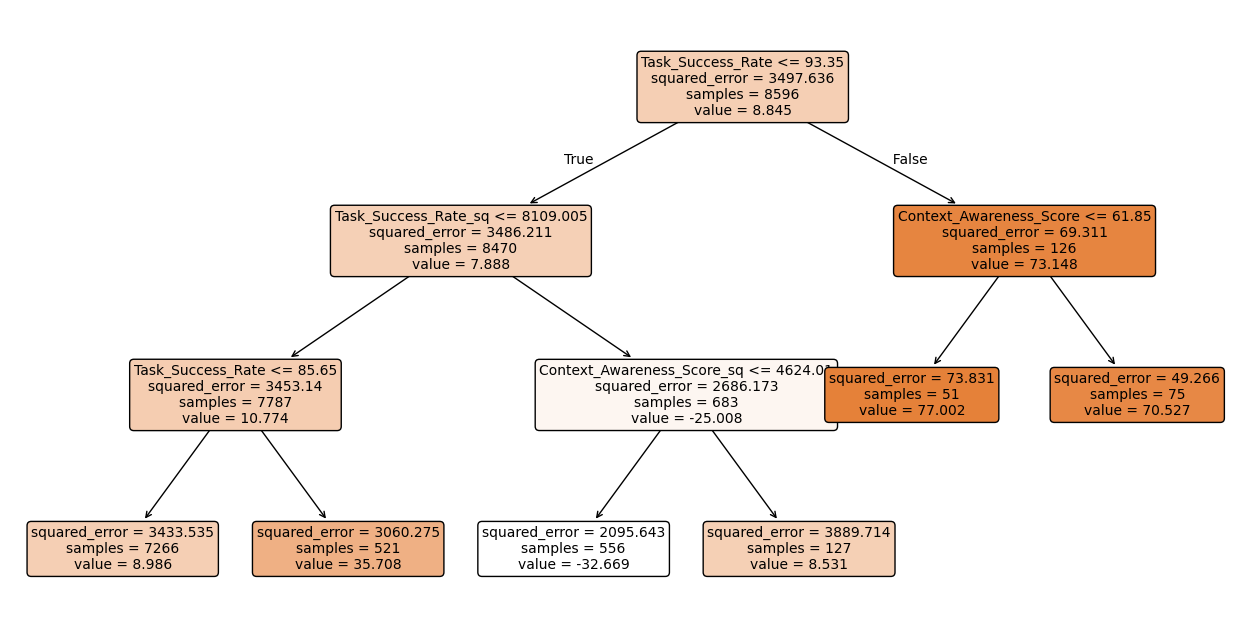

In [ ]:
plt.figure(figsize=(16, 8))
plot_tree(
    tree_model,
    feature_names=X_tree.columns,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.show()